# Forecasting Permintaan Weekly

Dataset: Store Item Demand Forecasting (Kaggle), 10 toko × 50 item, 2013 s/d 2017
Tujuan: memprediksi penjualan mingguan 2018

In [ ]:
# import library
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")

### 1. Load & Check Data

In [ ]:
# load data
df = pd.read_csv("train.csv", parse_dates=["date"])
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [ ]:
# cek bentuk & type data
print(df.shape)
df.info()

(913000, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[ns]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 27.9 MB


Data berisi 913.000 baris dan 4 kolom. Kolom `date` sudah bertipe tanggal

In [ ]:
# cek missing & duplicate data
print(df.isna().sum())
print("duplikat:", df.duplicated(["date", "store", "item"]).sum())

date     0
store    0
item     0
sales    0
dtype: int64
duplikat: 0


Tidak ada nilai kosong dan tidak ada baris ganda.

In [ ]:
# rentang waktu dan jumlah deret
print(df["date"].min(), "sampai", df["date"].max())
print("jumlah hari unik:", df["date"].nunique())
print("toko:", df["store"].nunique(), "| item:", df["item"].nunique())
print(df.groupby(["store", "item"]).size().describe())

2013-01-01 00:00:00 sampai 2017-12-31 00:00:00
jumlah hari unik: 1826
toko: 10 | item: 50
count     500.0
mean     1826.0
std         0.0
min      1826.0
25%      1826.0
50%      1826.0
75%      1826.0
max      1826.0
dtype: float64


Data mencakup 1 Januari 2013 sampai 31 Desember 2017 (1.826 hari). Dengan 10 toko dan 50 item ada 500 deret waktu, dan semuanya punya jumlah baris yang sama, jadi tidak ada hari yang hilang.

In [ ]:
# cek nilai penjualan
print(df["sales"].describe())
print("penjualan nol:", (df["sales"] == 0).sum())

count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64
penjualan nol: 1


Penjualan harian rata-rata sekitar 52 unit, dengan nilai tertinggi 231. Hanya satu baris yang bernilai nol. Data tidak memuat informasi stok, jadi penjualan dianggap sama dengan permintaan.

### 2. Exploratory Data Analysis

In [ ]:
# siapkan kolom waktu
df["tahun"] = df["date"].dt.year
df["bulan"] = df["date"].dt.month
df["hari"] = df["date"].dt.dayofweek   # 0 = senin, 6 = minggu

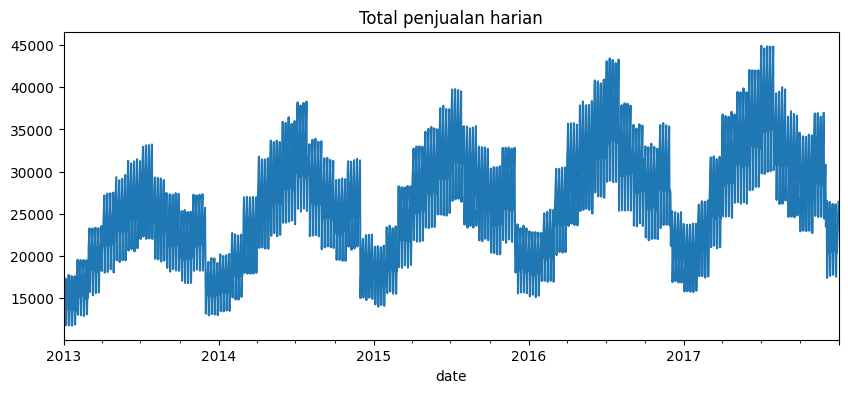

In [ ]:
# total penjualan harian
harian = df.groupby("date")["sales"].sum()
harian.plot(figsize=(10, 4), title="Total penjualan harian")
plt.show()

Penjualan naik turun mengikuti pola yang berulang tiap tahun: rendah di awal dan akhir tahun, tinggi di pertengahan tahun. Puncak tiap tahun juga lebih tinggi dari sebelumnya, jadi ada tren naik. Garis yang terlihat tebal menandakan pola mingguan yang kuat.

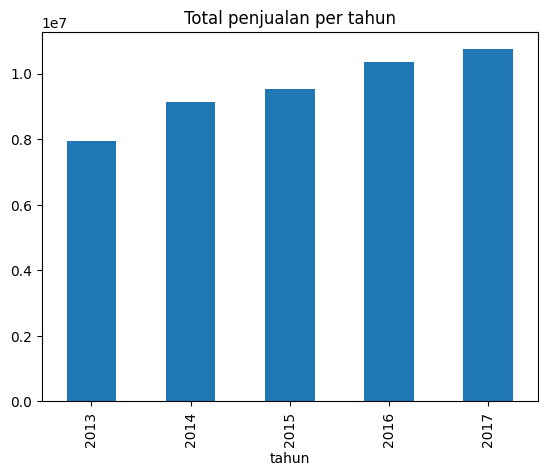

tahun
2013      NaN
2014    0.150
2015    0.044
2016    0.086
2017    0.036
Name: sales, dtype: float64


In [ ]:
# tren tahunan
tahunan = df.groupby("tahun")["sales"].sum()
tahunan.plot(kind="bar", title="Total penjualan per tahun")
plt.show()
print(tahunan.pct_change().round(3))

Total penjualan naik tiap tahun, dari sekitar 7,9 juta unit (2013) menjadi 10,7 juta (2017). Kenaikan terbesar ada di 2014 (sekitar 15%), sedangkan 2017 hanya sekitar 4%, jadi pertumbuhannya melambat.

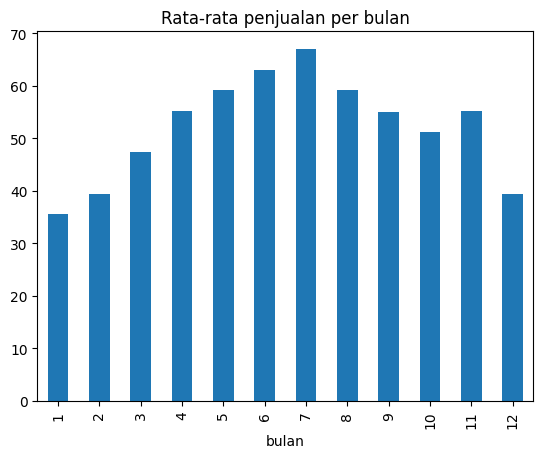

In [ ]:
# pola bulanan
df.groupby("bulan")["sales"].mean().plot(kind="bar", title="Rata-rata penjualan per bulan")
plt.show()

Rata-rata penjualan harian terendah ada di Januari (sekitar 35 unit) dan tertinggi di Juli (sekitar 67 unit), hampir dua kali lipat. Desember turun lagi ke sekitar 39 unit.

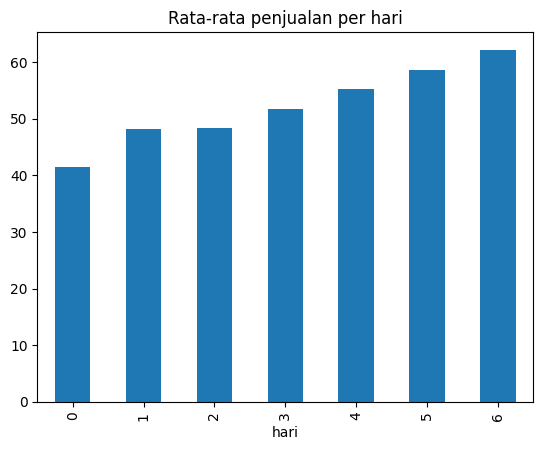

In [ ]:
# pola hari dalam seminggu
df.groupby("hari")["sales"].mean().plot(kind="bar", title="Rata-rata penjualan per hari")
plt.show()

Penjualan naik bertahap dari Senin (sekitar 41 unit) ke Minggu (sekitar 62 unit), selisih sekitar 50%. Pada grafik, angka 0 berarti Senin dan 6 berarti Minggu.

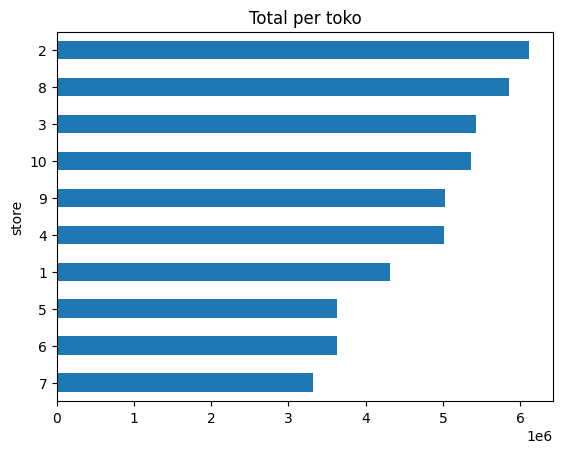

In [ ]:
# perbandingan total penjualan antar toko
df.groupby("store")["sales"].sum().sort_values().plot(kind="barh", title="Total per toko")
plt.show()

Skala antar toko berbeda: toko 2 terbesar (sekitar 6,1 juta unit) dan toko 7 terkecil (sekitar 3,3 juta), selisih sekitar 1,8 kali.

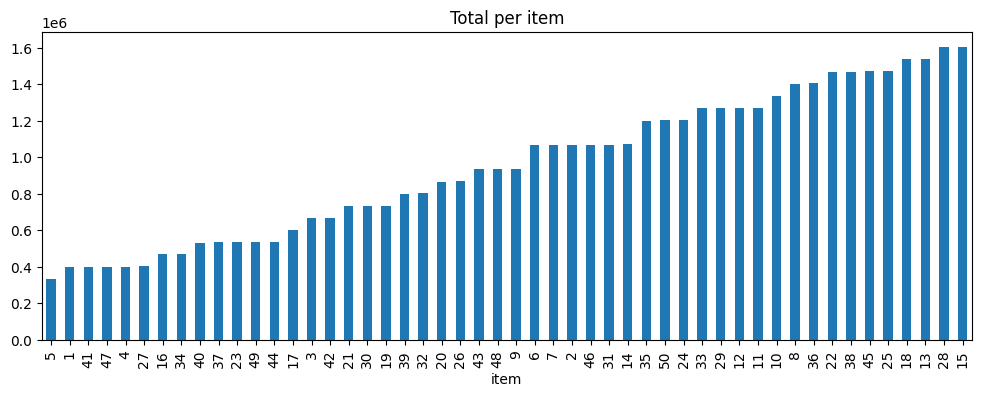

In [ ]:
# perbandingan total penjualan antar item
df.groupby("item")["sales"].sum().sort_values().plot(kind="bar", figsize=(12, 4), title="Total per item")
plt.show()

Perbedaan antar item lebih besar: item 15 dan 28 terlaris (sekitar 1,6 juta unit), item 5 paling rendah (sekitar 335 ribu), selisih sekitar 4,8 kali. Beberapa item punya total hampir sama persis, tanda umum data sintetis.

Dari hasil eksplorasi, penjualan memiliki tiga pola utama: tren naik tahunan, musiman bulanan (puncak di pertengahan tahun), dan pola mingguan (puncak di akhir pekan). Skala penjualan juga berbeda cukup jauh antar toko dan antar item. Temuan ini menjadi dasar pemilihan metode forecast pada tahap berikutnya.

### 3. Train Test & Baseline

In [ ]:
# bagi data berdasarkan waktu: latih 2013-2016, uji 2017
train = df[df["date"] < "2017-01-01"]
test = df[df["date"] >= "2017-01-01"]

print("train:", train["date"].min().date(), "-", train["date"].max().date(), len(train))
print("test :", test["date"].min().date(), "-", test["date"].max().date(), len(test))

train: 2013-01-01 - 2016-12-31 730500
test : 2017-01-01 - 2017-12-31 182500


Data latih mencakup 2013 sampai 2016 (730.500 baris) dan data uji 2017 (182.500 baris). Pembagian memakai urutan waktu, supaya model tidak melihat data masa depan.

In [ ]:
# ubah ke bentuk lebar: satu kolom = satu deret (toko, item)
wide_train = train.pivot_table(index="date", columns=["store", "item"], values="sales")
wide_test = test.pivot_table(index="date", columns=["store", "item"], values="sales")
n = len(wide_test)

In [ ]:
# bangun tiga baseline
def tabel(pred):
    # bungkus hasil prediksi jadi tabel dengan bentuk yang sama seperti data uji
    return pd.DataFrame(pred, index=wide_test.index, columns=wide_test.columns)

# 1. naive: semua hari = penjualan hari terakhir di train
naive = tabel(np.tile(wide_train.iloc[-1].values, (n, 1)))

# 2. rata-rata 28 hari terakhir, dipakai datar
ma28 = tabel(np.tile(wide_train.tail(28).mean().values, (n, 1)))

# 3. seasonal naive: ulang pola 364 hari terakhir (52 minggu penuh)
last_year = wide_train.tail(364).values
snaive = tabel(np.array([last_year[i % 364] for i in range(n)]))

In [ ]:
# ukur error baseline
def mae(a, p):
    a, p = np.asarray(a), np.asarray(p)
    return np.abs(a - p).mean()

def wmape(a, p):
    a, p = np.asarray(a), np.asarray(p)
    return np.abs(a - p).sum() / a.sum()

hasil = pd.DataFrame({
    "MAE": {"Naive": mae(wide_test, naive), "Rata-rata 28 hari": mae(wide_test, ma28), "Seasonal naive": mae(wide_test, snaive)},
    "WMAPE": {"Naive": wmape(wide_test, naive), "Rata-rata 28 hari": wmape(wide_test, ma28), "Seasonal naive": wmape(wide_test, snaive)},
}).round(3)
hasil

,MAE,WMAPE
Naive,16.099,0.274
Rata-rata 28 hari,18.133,0.308
Seasonal naive,8.556,0.145


Pada data harian, seasonal naive paling akurat (error 14,5%), jauh di bawah naive (27,4%) dan rata-rata 28 hari (30,8%). Dua baseline lainnya memperlakukan semua hari sama, padahal pola mingguan dan musimannya kuat. Angka 14,5% menjadi patokan yang harus dikalahkan model.

### 4. Holt-Winters: Satu Deret dan 500 Deret

In [ ]:
# siapkan deret mingguan
def mingguan(d):
    s = d.set_index("date")["sales"]["2013-01-06":]   # mulai dari hari minggu pertama
    w = s.resample("W-SAT").sum()                     # satu minggu = minggu sampai sabtu
    return w.iloc[:208], w.iloc[208:260]              # latih 208 minggu, uji 52 minggu

# contoh satu deret: toko 1, item 1
d1 = df[(df["store"] == 1) & (df["item"] == 1)]
tr1, te1 = mingguan(d1)
print(len(tr1), len(te1))

208 52


Data harian diubah menjadi mingguan untuk satu deret (toko 1, item 1): 208 minggu untuk latihan dan 52 minggu untuk uji. Holt-Winters hanya bisa menangani satu siklus musiman, jadi dipakai siklus 52 minggu.

In [ ]:
# bandingkan holt-winters dengan seasonal naive
snaive1 = tr1.tail(52).values

model1 = ExponentialSmoothing(tr1, trend="add", seasonal="add", seasonal_periods=52).fit()
ets1 = model1.forecast(52)

print("seasonal naive:", round(wmape(te1, snaive1), 3))
print("Holt-Winters  :", round(wmape(te1, ets1), 3))

seasonal naive: 0.096
Holt-Winters  : 0.075


Pada deret ini Holt-Winters punya error 7,5%, lebih kecil dari seasonal naive (9,6%).

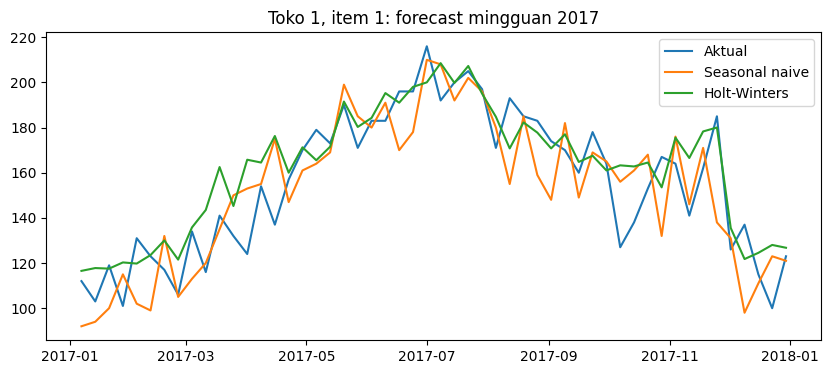

In [ ]:
# grafik aktual vs seasonal naive vs holt-winters
plt.figure(figsize=(10, 4))
plt.plot(te1.index, te1.values, label="Aktual")
plt.plot(te1.index, snaive1, label="Seasonal naive")
plt.plot(te1.index, ets1.values, label="Holt-Winters")
plt.legend()
plt.title("Toko 1, item 1: forecast mingguan 2017")
plt.show()

Garis Holt-Winters (hijau) mengikuti bentuk musiman dengan baik: naik dari awal tahun, memuncak sekitar Juli, lalu turun di akhir tahun. Seasonal naive (oranye) menyalin naik turun tahun lalu apa adanya, sehingga lonjakannya sering meleset beberapa minggu. Holt-Winters kurang peka terhadap penurunan mendadak, misalnya di sekitar Oktober.

In [ ]:
# ulangi untuk semua 500 deret (sekitar 2 menit)
A, P_sn, P_ets = [], [], []

for (st, it), g in df.groupby(["store", "item"]):
    tr, te = mingguan(g)
    A.append(te.values)                       # penjualan aktual 2017
    P_sn.append(tr.tail(52).values)           # seasonal naive
    P_ets.append(ExponentialSmoothing(tr, trend="add", seasonal="add", seasonal_periods=52).fit().forecast(52).values)

A, P_sn, P_ets = np.array(A), np.array(P_sn), np.array(P_ets)

print("seasonal naive:", round(wmape(A, P_sn), 3))
print("Holt-Winters  :", round(wmape(A, P_ets), 3))

seasonal naive: 0.062
Holt-Winters  : 0.055


Pada seluruh 500 deret, Holt-Winters mencatat error 5,5% dibanding 6,2% untuk seasonal naive. Hasilnya searah dengan contoh satu deret.

### 5. Perbandingan Model dan Baseline

In [ ]:
# tabel ringkasan: mae, wmape, bias (bias > 0 = forecast terlalu tinggi)
hasil = pd.DataFrame({
    "MAE": {"Seasonal naive": mae(A, P_sn), "Holt-Winters": mae(A, P_ets)},
    "WMAPE": {"Seasonal naive": wmape(A, P_sn), "Holt-Winters": wmape(A, P_ets)},
    "Bias": {"Seasonal naive": (P_sn - A).sum() / A.sum(), "Holt-Winters": (P_ets - A).sum() / A.sum()},
}).round(3)
hasil

,MAE,WMAPE,Bias
Seasonal naive,25.545,0.062,-0.037
Holt-Winters,22.749,0.055,0.019


Holt-Winters lebih akurat dari seasonal naive: MAE 22,7 vs 25,5 unit per minggu, WMAPE 5,5% vs 6,2%. Seasonal naive cenderung meramal terlalu rendah (bias -3,7%) karena menyalin tahun lalu sementara penjualan terus naik, sedangkan Holt-Winters sedikit terlalu tinggi (+1,9%). Untuk stok, forecast terlalu rendah berisiko kehabisan barang dan terlalu tinggi berisiko menumpuk.

In [ ]:
# error per toko
idx = df.groupby(["store", "item"]).size().index   # urutan sama dengan loop sebelumnya
err = pd.DataFrame({
    "store": idx.get_level_values("store"),
    "item": idx.get_level_values("item"),
    "aktual": A.sum(axis=1),
    "err_sn": np.abs(A - P_sn).sum(axis=1),
    "err_ets": np.abs(A - P_ets).sum(axis=1),
})

per_toko = err.groupby("store")[["aktual", "err_sn", "err_ets"]].sum()
per_toko["WMAPE seasonal naive"] = per_toko["err_sn"] / per_toko["aktual"]
per_toko["WMAPE Holt-Winters"] = per_toko["err_ets"] / per_toko["aktual"]
per_toko[["WMAPE seasonal naive", "WMAPE Holt-Winters"]].round(3)

,WMAPE seasonal naive,WMAPE Holt-Winters
store,,
1,0.065,0.058
2,0.056,0.051
3,0.060,0.052
4,0.061,0.055
5,0.069,0.061
6,0.069,0.061
7,0.071,0.063
8,0.058,0.052
9,0.062,0.053


Holt-Winters lebih akurat di semua 10 toko, dengan selisih sekitar 0,5 sampai 0,9 poin persen. Toko 5, 6, dan 7 punya error tertinggi di kedua metode, dan ketiganya juga toko dengan penjualan terkecil.

In [ ]:
# error per kuartal (13 minggu per kuartal)
for i, nama in enumerate(["Q1", "Q2", "Q3", "Q4"]):
    a, b = i * 13, (i + 1) * 13
    print(nama, "| seasonal naive:", round(wmape(A[:, a:b], P_sn[:, a:b]), 3),
          "| Holt-Winters:", round(wmape(A[:, a:b], P_ets[:, a:b]), 3))

Q1 | seasonal naive: 0.066 | Holt-Winters: 0.086
Q2 | seasonal naive: 0.058 | Holt-Winters: 0.042
Q3 | seasonal naive: 0.06 | Holt-Winters: 0.044
Q4 | seasonal naive: 0.066 | Holt-Winters: 0.059


Keunggulan Holt-Winters tidak merata sepanjang tahun. Di Q2 sampai Q4 model lebih akurat (error 4,2% sampai 5,9%), tetapi di Q1 justru kalah dari seasonal naive (8,6% vs 6,6%). Penyebabnya belum diselidiki, dan kuartal pertama perlu diwaspadai.

Holt-Winters dipilih sebagai model utama karena lebih akurat secara keseluruhan dan konsisten di seluruh toko. Seasonal naive tetap dipertahankan sebagai pembanding dan cadangan. Dua hal perlu dicatat sebagai keterbatasan: selisih akurasinya relatif kecil (sekitar 0,7 poin persen), dan performa Holt-Winters lebih lemah di kuartal pertama. Data juga bersifat sintetis, sehingga hasil di data nyata bisa berbeda.

### 6. Forecast 2018

In [ ]:
# siapkan deret mingguan dengan seluruh data (tanpa data uji)
def mingguan_penuh(d):
    s = d.set_index("date")["sales"]["2013-01-06":]
    w = s.resample("W-SAT").sum()
    return w.iloc[:260]    # 260 minggu penuh, sampai 30 Des 2017

Model dilatih ulang dengan seluruh data 2013 sampai 2017 (260 minggu penuh). Satu hari sisa di akhir 2017 dibuang karena belum membentuk satu minggu.

In [ ]:
# prediksi 52 minggu ke depan untuk semua deret
hasil = []

for (st, it), g in df.groupby(["store", "item"]):
    seri = mingguan_penuh(g)
    fc = ExponentialSmoothing(seri, trend="add", seasonal="add", seasonal_periods=52).fit().forecast(52)
    hasil.append(pd.DataFrame({
        "store": st,
        "item": it,
        "minggu": fc.index,
        "forecast": fc.values.round(1),
    }))

forecast_2018 = pd.concat(hasil, ignore_index=True)
forecast_2018.head()

,store,item,minggu,forecast
0,1,1,2018-01-06,118.3
1,1,1,2018-01-13,117.5
2,1,1,2018-01-20,120.5
3,1,1,2018-01-27,119.2
4,1,1,2018-02-03,124.8


Tiap baris berisi satu toko, satu item, dan satu minggu (tanggal akhir minggu jatuh pada hari Sabtu). Untuk toko 1 item 1, forecast lima minggu pertama 2018 ada di kisaran 117 sampai 125 unit.

In [ ]:
# cek kewajaran hasil forecast
print(forecast_2018.shape)
print(forecast_2018["minggu"].min().date(), "sampai", forecast_2018["minggu"].max().date())
print("kosong:", forecast_2018["forecast"].isna().sum(), "| negatif:", (forecast_2018["forecast"] < 0).sum())

total_2017 = df[df["date"].dt.year == 2017]["sales"].sum()
total_2018 = forecast_2018["forecast"].sum()
print("Total aktual 2017:", total_2017)
print("Total forecast 2018:", round(total_2018))
print("Selisih:", round(total_2018 / total_2017 - 1, 3))

(26000, 4)
2018-01-06 sampai 2018-12-29
kosong: 0 | negatif: 0
Total aktual 2017: 10733740
Total forecast 2018: 11236704
Selisih: 0.047


Tabel berisi 26.000 baris (500 deret × 52 minggu) untuk 6 Januari sampai 29 Desember 2018, tanpa nilai kosong atau negatif. Total forecast 2018 sekitar 11,24 juta unit, naik 4,7% dari penjualan 2017 (10,73 juta). Angka ini masuk akal: pertumbuhan 2016 sebesar 8,6% dan 2017 sebesar 3,6%, jadi 4,7% lebih dekat ke laju terbaru.

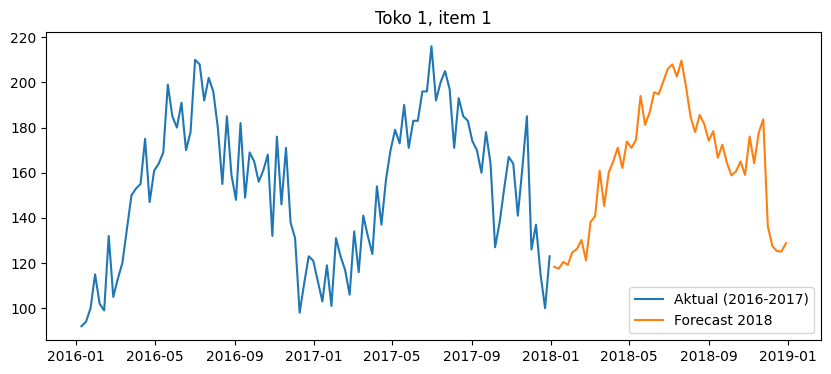

In [ ]:
# grafik contoh: toko 1, item 1 (aktual 2016-2017 dan forecast 2018)
seri = mingguan_penuh(df[(df["store"] == 1) & (df["item"] == 1)])
fc1 = forecast_2018[(forecast_2018["store"] == 1) & (forecast_2018["item"] == 1)].set_index("minggu")["forecast"]

plt.figure(figsize=(10, 4))
plt.plot(seri.index[-104:], seri.values[-104:], label="Aktual (2016-2017)")
plt.plot(fc1.index, fc1.values, label="Forecast 2018")
plt.legend()
plt.title("Toko 1, item 1")
plt.show()

Forecast melanjutkan pola dua tahun sebelumnya: naik dari Januari, memuncak sekitar Juli di kisaran 210 unit, lalu turun ke 125 sampai 130 unit di akhir tahun. Garisnya agak bergerigi karena model ikut menyalin sedikit naik turun tahun lalu, jadi yang bisa dipegang adalah pola besarnya, bukan lonjakan per minggu.

In [ ]:
# simpan hasil forecast
forecast_2018.to_csv("forecast_2018.csv", index=False)